1. Importing libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

2. Load and understand the data

In [2]:
DATA_PATH = r'C:\Users\aditi\Desktop\supply_food_chain\perishable_goods_management.csv'
df = pd.read_csv(DATA_PATH)

print('Dataset shape:', df.shape)
display(df.head())
display(df['was_spoiled'].value_counts().rename_axis('was_spoiled').to_frame('records'))
df.info()

Dataset shape: (100000, 42)


,record_id,product_id,product_name,category,store_id,region,supplier_id,transaction_date,expiration_date,shelf_life_days,days_remaining_at_purchase,storage_temp,temp_deviation,base_price,cost_price,initial_quantity,spoilage_sensitivity,day_of_week,is_weekend,month,daily_demand,demand_variability,temp_abuse_events,distribution_hours,handling_score,packaging_score,spoilage_risk,was_spoiled,quality_grade,days_until_expiry,markdown_applied,discount_pct,selling_price,units_sold,units_wasted,waste_pct,revenue,waste_cost,profit,profit_margin_pct,supplier_score,is_promoted
0,1,BAK_DON_743,Donuts,Bakery,STORE_046,West,SUPPLIER_03,2024-09-25,2024-09-29,4,4,21.0,1.0,2.60,1.22,158,0.50,2,0,9,54,0.35,0,41.5,9,10,0.099,0,A,2,0,0.00,2.60,138,20,12.7,358.80,24.40,166.04,46.3,9,0
1,2,MEA_SAU_338,Sausages,Meat,STORE_030,Southwest,SUPPLIER_12,2023-04-14,2023-04-21,9,7,0.7,0.3,8.25,4.18,353,0.90,4,0,4,55,0.35,0,38.7,8,8,0.172,0,A,4,0,0.00,8.25,251,102,28.9,2070.75,426.36,595.21,28.7,6,0
2,3,BAK_BAG_799,Bagels,Bakery,STORE_035,Midwest,SUPPLIER_08,2024-10-25,2024-10-27,2,2,21.3,1.3,4.12,2.12,483,0.50,4,0,10,331,0.35,0,54.1,4,8,0.201,0,B,0,1,0.69,1.28,483,0,0.0,618.24,0.00,-405.72,-65.6,9,0
3,4,PHA_VAC_801,Vaccines,Pharmaceuticals,STORE_003,Midwest,SUPPLIER_11,2023-11-29,2024-02-17,87,80,8.0,3.0,209.56,87.99,477,0.85,2,0,11,7,0.38,0,70.1,5,9,0.230,0,B,79,0,0.00,209.56,477,0,0.0,99960.12,0.00,57988.89,58.0,6,0
4,5,REA_FRE_422,Fresh Pasta,Ready_to_Eat,STORE_042,West,SUPPLIER_15,2023-08-06,2023-08-09,4,3,3.5,0.5,6.86,3.03,391,0.90,6,1,8,169,0.25,0,64.9,5,6,0.268,0,C,3,1,0.23,5.28,391,0,0.0,2064.48,0.00,879.75,42.6,6,0


,records
was_spoiled,
0,80558
1,19442


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 42 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   record_id                   100000 non-null  int64  
 1   product_id                  100000 non-null  object 
 2   product_name                100000 non-null  object 
 3   category                    100000 non-null  object 
 4   store_id                    100000 non-null  object 
 5   region                      100000 non-null  object 
 6   supplier_id                 100000 non-null  object 
 7   transaction_date            100000 non-null  object 
 8   expiration_date             100000 non-null  object 
 9   shelf_life_days             100000 non-null  int64  
 10  days_remaining_at_purchase  100000 non-null  int64  
 11  storage_temp                100000 non-null  float64
 12  temp_deviation              100000 non-null  float64
 13  base_price     

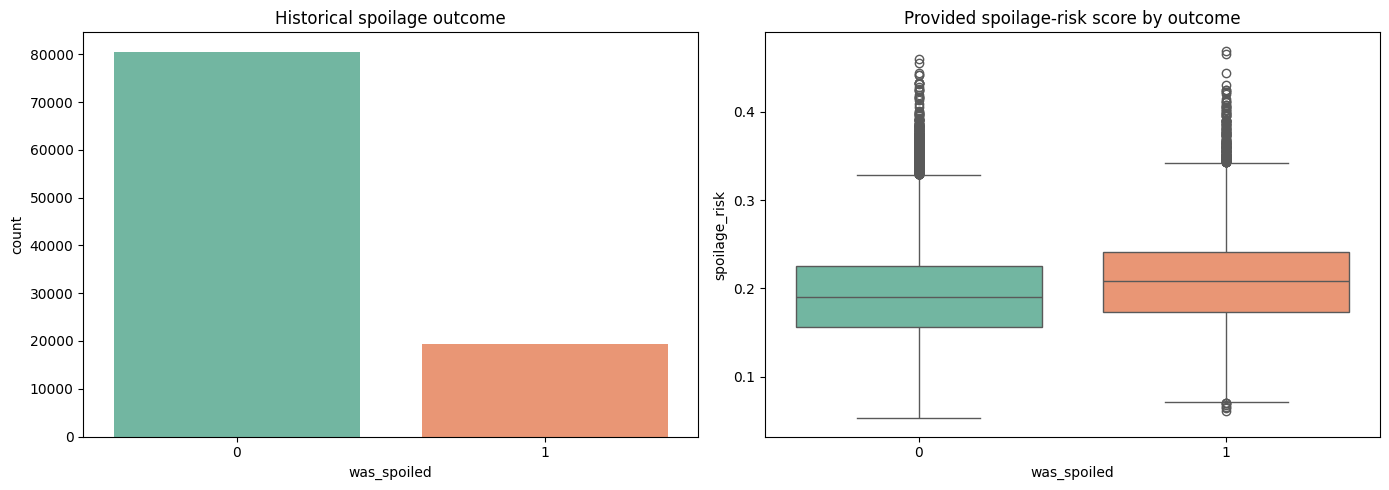

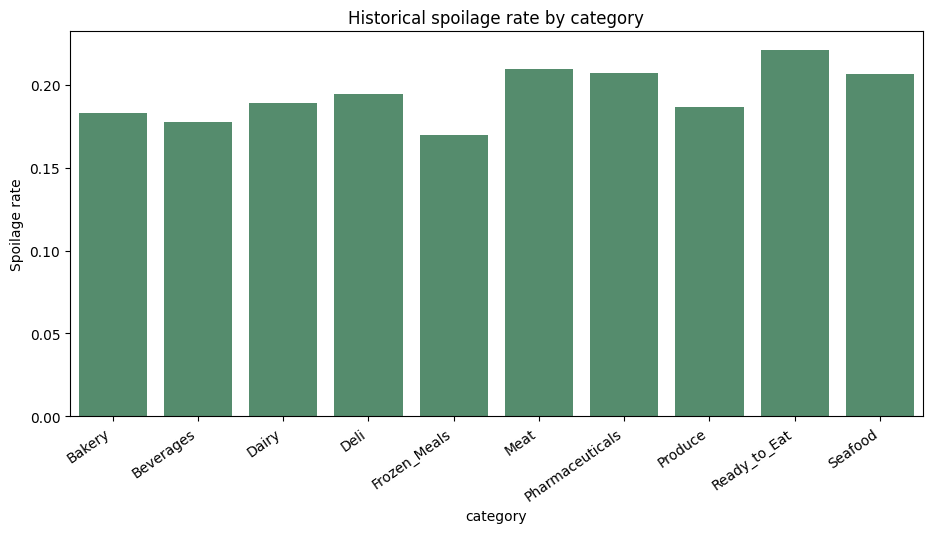

In [3]:
# Quick exploratory analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x='was_spoiled', ax=axes[0], palette='Set2')
axes[0].set_title('Historical spoilage outcome')
sns.boxplot(data=df, x='was_spoiled', y='spoilage_risk', ax=axes[1], palette='Set2')
axes[1].set_title('Provided spoilage-risk score by outcome')
plt.tight_layout()

plt.figure(figsize=(11, 5))
sns.barplot(data=df.groupby('category', as_index=False)['was_spoiled'].mean(), x='category', y='was_spoiled', color='#4C956C')
plt.xticks(rotation=35, ha='right')
plt.title('Historical spoilage rate by category')
plt.ylabel('Spoilage rate')
plt.show()

3. Data preprocessing and feature selection

In [4]:
# Use the operational expiry measure, and remove regulated non-food inventory.
model_df = df[df['category'].ne('Pharmaceuticals')].copy()
model_df['days_until_expiry'] = model_df['days_until_expiry'].clip(lower=0)

numeric_features = [
    'shelf_life_days', 'days_remaining_at_purchase', 'days_until_expiry',
    'storage_temp', 'temp_deviation', 'spoilage_sensitivity', 'daily_demand',
    'demand_variability', 'temp_abuse_events', 'distribution_hours',
    'handling_score', 'packaging_score', 'spoilage_risk', 'supplier_score'
]
categorical_features = ['category', 'region', 'day_of_week', 'is_weekend', 'month']
features = numeric_features + categorical_features
target = 'was_spoiled'

X = model_df[features]
y = model_df[target].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median'))])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

print('Training rows:', X_train.shape[0], '| Test rows:', X_test.shape[0])

Training rows: 71904 | Test rows: 17976


4. Supervised model: Random Forest classifier

In [5]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))
])

param_grid = {
    'model__n_estimators': [150, 250],
    'model__max_depth': [None, 14],
    'model__min_samples_leaf': [1, 3]
}
search = GridSearchCV(pipeline, param_grid, scoring='roc_auc', cv=3, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print('Best parameters:', search.best_params_)
print('Best cross-validation ROC-AUC:', round(search.best_score_, 3))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__max_depth': 14, 'model__min_samples_leaf': 3, 'model__n_estimators': 250}
Best cross-validation ROC-AUC: 0.586


6. Select food for donation

In [6]:
# Score all food rows (pharmaceuticals remain excluded).
model_df['predicted_spoilage_probability'] = best_model.predict_proba(model_df[features])[:, 1]
DONATION_RISK_THRESHOLD = 0.50
MAX_DAYS_TO_EXPIRY = 3

selected_for_donation = model_df.loc[
    (model_df['days_until_expiry'].between(0, MAX_DAYS_TO_EXPIRY))
    & (model_df['predicted_spoilage_probability'] >= DONATION_RISK_THRESHOLD),
    ['record_id', 'product_id', 'product_name', 'category', 'store_id', 'region',
     'expiration_date', 'days_until_expiry', 'initial_quantity', 'units_sold',
     'spoilage_risk', 'predicted_spoilage_probability']
].copy()

selected_for_donation['available_units'] = (
    selected_for_donation['initial_quantity'] - selected_for_donation['units_sold']
).clip(lower=0).astype(int)
selected_for_donation = selected_for_donation.query('available_units > 0').sort_values(
    ['predicted_spoilage_probability', 'days_until_expiry'], ascending=[False, True]
)

print('Food records selected for donation:', len(selected_for_donation))
print('Potential units diverted from waste:', selected_for_donation['available_units'].sum())
display(selected_for_donation.head(15))
selected_for_donation.to_csv('food_selected_for_donation.csv', index=False)
print('Saved: food_selected_for_donation.csv')

Food records selected for donation: 7145
Potential units diverted from waste: 575524


,record_id,product_id,product_name,category,store_id,region,expiration_date,days_until_expiry,initial_quantity,units_sold,spoilage_risk,predicted_spoilage_probability,available_units
9616,9617,REA_SUS_141,Sushi,Ready_to_Eat,STORE_008,West,2023-06-27,0,264,184,0.385,0.748481,80
77332,77333,REA_SUS_915,Sushi,Ready_to_Eat,STORE_027,Midwest,2024-07-27,0,240,168,0.325,0.746481,72
40179,40180,REA_SAN_100,Sandwiches,Ready_to_Eat,STORE_044,Northeast,2024-02-09,0,473,331,0.295,0.736972,142
69277,69278,REA_SAL_520,Salads,Ready_to_Eat,STORE_003,Midwest,2023-01-15,0,191,133,0.300,0.736339,58
36702,36703,REA_SAL_368,Salads,Ready_to_Eat,STORE_013,Northeast,2024-08-26,0,195,136,0.346,0.735361,59
75106,75107,REA_SUS_677,Sushi,Ready_to_Eat,STORE_004,Southeast,2023-01-20,0,161,112,0.395,0.733299,49
37446,37447,REA_SAN_264,Sandwiches,Ready_to_Eat,STORE_018,West,2024-08-07,0,228,159,0.276,0.732753,69
36419,36420,REA_SOU_932,Soups,Ready_to_Eat,STORE_036,Northeast,2024-01-16,0,462,323,0.387,0.732635,139
27063,27064,REA_SOU_291,Soups,Ready_to_Eat,STORE_026,West,2024-02-15,0,250,175,0.422,0.730944,75
10734,10735,REA_SAN_418,Sandwiches,Ready_to_Eat,STORE_003,Midwest,2024-06-05,0,123,86,0.380,0.729711,37


Saved: food_selected_for_donation.csv


In [7]:
"""
EcoTrace: Food Waste Supply Chain And Relief Router
Phase 3: Shortest-Path NGO Matching & Logistics Dispatch
Filename: relief_router.py
"""

import math
import pandas as pd
import numpy as np

# ------------------------------------------------------------------------------
# 1. HAVERSINE DISTANCE ALGORITHM
# ------------------------------------------------------------------------------
def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Computes the great-circle distance between two GPS coordinates in kilometers.
    """
    R = 6371.0  # Earth's radius in kilometers
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    
    a = (math.sin(dlat / 2) ** 2 + 
         math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon / 2) ** 2)
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    
    return round(R * c, 2)


# ------------------------------------------------------------------------------
# 2. NGO DIRECTORY & REGIONAL STORE COORDINATES
# ------------------------------------------------------------------------------
# Pre-registered NGOs with their maximum daily unit capacities and GPS coordinates
NGO_DIRECTORY = [
    {"ngo_id": "NGO_NE_01", "name": "City Harvest Food Rescue", "city": "New York", "state": "NY", "region": "Northeast", "lat": 40.7128, "lon": -74.0060, "capacity": 300000},
    {"ngo_id": "NGO_NE_02", "name": "Greater Boston Food Bank", "city": "Boston", "state": "MA", "region": "Northeast", "lat": 42.3601, "lon": -71.0589, "capacity": 250000},
    {"ngo_id": "NGO_SE_01", "name": "Atlanta Community Food Bank", "city": "Atlanta", "state": "GA", "region": "Southeast", "lat": 33.7490, "lon": -84.3880, "capacity": 200000},
    {"ngo_id": "NGO_SE_02", "name": "Feeding South Florida", "city": "Pembroke Park", "state": "FL", "region": "Southeast", "lat": 26.1224, "lon": -80.1373, "capacity": 200000},
    {"ngo_id": "NGO_MW_01", "name": "Greater Chicago Food Depository", "city": "Chicago", "state": "IL", "region": "Midwest", "lat": 41.8781, "lon": -87.6298, "capacity": 200000},
    {"ngo_id": "NGO_MW_02", "name": "Mid-Ohio Food Collective", "city": "Grove City", "state": "OH", "region": "Midwest", "lat": 39.9612, "lon": -82.9988, "capacity": 180000},
    {"ngo_id": "NGO_W_01",  "name": "Los Angeles Regional Food Bank", "city": "Los Angeles", "state": "CA", "region": "West", "lat": 34.0522, "lon": -118.2437, "capacity": 220000},
    {"ngo_id": "NGO_W_02",  "name": "SF-Marin Food Bank", "city": "San Francisco", "state": "CA", "region": "West", "lat": 37.7749, "lon": -122.4194, "capacity": 200000},
    {"ngo_id": "NGO_SW_01", "name": "North Texas Food Bank", "city": "Plano", "state": "TX", "region": "Southwest", "lat": 32.7767, "lon": -96.7970, "capacity": 160000},
    {"ngo_id": "NGO_SW_02", "name": "Central Texas Food Bank", "city": "Austin", "state": "TX", "region": "Southwest", "lat": 30.2672, "lon": -97.7431, "capacity": 150000}
]

# Base coordinates for the 5 geographic regions
REGION_STORE_COORDS = {
    "Northeast": (41.5000, -73.5000),
    "Southeast": (31.5000, -82.5000),
    "Midwest":   (41.0000, -85.0000),
    "West":      (36.0000, -119.0000),
    "Southwest": (31.0000, -97.0000)
}


# ------------------------------------------------------------------------------
# 3. LOAD DATA & INITIALIZE WAREHOUSE LOCATIONS
# ------------------------------------------------------------------------------
# Load the safe food records generated by the Phase 2 Machine Learning script
input_csv = "food_selected_for_donation.csv"
print(f"[INFO] Loading shortlisted food batches from '{input_csv}'...")
df_don = pd.read_csv(input_csv)

# Assign deterministic GPS coordinates to the 50 origin stores based on their region
np.random.seed(42)
store_coords = {}
for store in df_don["store_id"].unique():
    region = df_don.loc[df_don["store_id"] == store, "region"].iloc[0]
    base_lat, base_lon = REGION_STORE_COORDS[region]
    store_coords[store] = (
        round(base_lat + np.random.uniform(-0.8, 0.8), 4),
        round(base_lon + np.random.uniform(-0.8, 0.8), 4)
    )

# Track how much daily capacity each NGO has remaining
ngo_remaining_cap = {ngo["ngo_id"]: ngo["capacity"] for ngo in NGO_DIRECTORY}


# ------------------------------------------------------------------------------
# 4. NEAREST-NEIGHBOR ROUTING ALGORITHM
# ------------------------------------------------------------------------------
assigned_ngos = []
assigned_ngo_names = []
assigned_cities = []
assigned_distances = []
est_transit_hours = []

print("[INFO] Computing shortest transit paths to partner NGOs...")

# Loop through every single batch of food to find the closest available shelter
for _, row in df_don.iterrows():
    store_lat, store_lon = store_coords[row["store_id"]]
    region = row["region"]
    units = row["available_units"]
    
    # Filter to only look at NGOs within the same geographic region
    candidate_ngos = [n for n in NGO_DIRECTORY if n["region"] == region]
    
    best_ngo = None
    min_dist = float("inf")
    
    # Compare distances to all regional NGOs and check capacity constraints
    for ngo in candidate_ngos:
        dist = haversine_distance(store_lat, store_lon, ngo["lat"], ngo["lon"])
        if dist < min_dist and ngo_remaining_cap[ngo["ngo_id"]] >= units:
            min_dist = dist
            best_ngo = ngo
            
    # Fallback to the closest NGO if all capacities are theoretically full
    if best_ngo is None:
        best_ngo = candidate_ngos[0]
        min_dist = haversine_distance(store_lat, store_lon, best_ngo["lat"], best_ngo["lon"])
    
    # Deduct the food units from the chosen NGO's daily capacity
    ngo_remaining_cap[best_ngo["ngo_id"]] -= units
    
    # Record the routing decisions
    assigned_ngos.append(best_ngo["ngo_id"])
    assigned_ngo_names.append(best_ngo["name"])
    assigned_cities.append(f"{best_ngo['city']}, {best_ngo['state']}")
    assigned_distances.append(min_dist)
    
    # Estimate logistics time: Assume delivery vans travel at 50 km/h with a 0.5hr loading buffer
    transit_time = round((min_dist / 50.0) + 0.5, 1)
    est_transit_hours.append(transit_time)

# Append the new logistical routing data to our DataFrame
df_don["store_lat"] = [store_coords[s][0] for s in df_don["store_id"]]
df_don["store_lon"] = [store_coords[s][1] for s in df_don["store_id"]]
df_don["assigned_ngo_id"] = assigned_ngos
df_don["assigned_ngo_name"] = assigned_ngo_names
df_don["ngo_location"] = assigned_cities
df_don["shortest_distance_km"] = assigned_distances
df_don["est_transit_hours"] = est_transit_hours

# Tag critical dispatches (items expiring today)
df_don["dispatch_urgency"] = np.where(df_don["days_until_expiry"] == 0, "Critical (Immediate)",
                             np.where(df_don["days_until_expiry"] == 1, "High Priority", "Standard Priority"))


# ------------------------------------------------------------------------------
# 5. EXPORT FINAL DISPATCH MANIFEST
# ------------------------------------------------------------------------------
output_excel = "EcoTrace_Relief_Router_Shortest_Path.xlsx"
print(f"[INFO] Exporting routing manifest to '{output_excel}'...")

# Write the final output to a clean Excel file using pandas
with pd.ExcelWriter(output_excel, engine="openpyxl") as writer:
    # Full dispatch checklist
    df_don.to_excel(writer, sheet_name="Shortest Path Dispatch", index=False)
    
    # Summarize NGO allocations
    ngo_summary = df_don.groupby(["assigned_ngo_id", "assigned_ngo_name", "region"]).agg(
        Total_Batches=("record_id", "count"),
        Total_Units_Received=("available_units", "sum"),
        Avg_Distance_KM=("shortest_distance_km", "mean")
    ).reset_index()
    ngo_summary["Avg_Distance_KM"] = ngo_summary["Avg_Distance_KM"].round(1)
    
    ngo_summary.to_excel(writer, sheet_name="NGO Deliveries Summary", index=False)

print("[SUCCESS] Routing complete. EcoTrace system workflow finished.")

[INFO] Loading shortlisted food batches from 'food_selected_for_donation.csv'...
[INFO] Computing shortest transit paths to partner NGOs...
[INFO] Exporting routing manifest to 'EcoTrace_Relief_Router_Shortest_Path.xlsx'...
[SUCCESS] Routing complete. EcoTrace system workflow finished.
